Analyze time-series fluorescence data from PURE (Protein synthesis Using Recombinant Elements) experiments. 

## Setup 

In [1]:
%load_ext autoreload
%autoreload 2
    
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Import the cdk platereader module
from cdk.analysis.cytosol import platereader as pr

# Set up plotting
pr.plot_setup()

## Load Data

In [2]:
# Specify file paths
data_file = "20260605-160608-cytation5-pure-timecourse-gfp-biotek-cdk.txt"
platemap_file = "20260605-GFP-ssrA-2.csv"


# Load data
data, platemap = pr.load_platereader_data(
    data_file=data_file,
    platemap_file=platemap_file,
    platereader="biotek-cdk"  # Options: "cytation", "envision", "biotek-cdk"
)

# Checkout first few rows
data.head()

,Time,Temperature,Well,Data,Row,Column,Read,Plate,Clock Time,Reader,Name
0,0 days 00:00:19,37.00,N5,269,N,5,GFP-Gext,Plate 1,2026-06-05 16:06:27,Cytation5,1.35 nM pT7- deGFP-ssrA + Purified ClpX + Puri...
1,0 days 00:05:19,37.00,N5,277,N,5,GFP-Gext,Plate 1,2026-06-05 16:11:27,Cytation5,1.35 nM pT7- deGFP-ssrA + Purified ClpX + Puri...
2,0 days 00:10:19,37.00,N5,878,N,5,GFP-Gext,Plate 1,2026-06-05 16:16:27,Cytation5,1.35 nM pT7- deGFP-ssrA + Purified ClpX + Puri...
3,0 days 00:15:19,37.00,N5,2204,N,5,GFP-Gext,Plate 1,2026-06-05 16:21:27,Cytation5,1.35 nM pT7- deGFP-ssrA + Purified ClpX + Puri...
4,0 days 00:20:19,37.10,N5,2938,N,5,GFP-Gext,Plate 1,2026-06-05 16:26:27,Cytation5,1.35 nM pT7- deGFP-ssrA + Purified ClpX + Puri...


## Plot Raw Curves

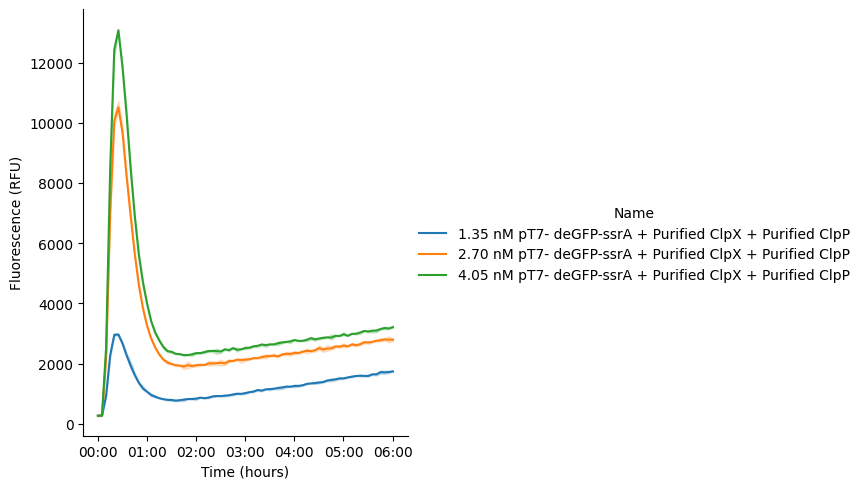

In [3]:
#| label: 20260605-degfp-ssra-2
g = pr.plot_curves(data=data)

## Normalize Data

In [4]:
data = pr.normalize_data_to_controls(data, ctrl_name = '10 uM HPTS')

Control name '10 uM HPTS' not found in data. No normalization applied.


Now replot your curves to see them normalized

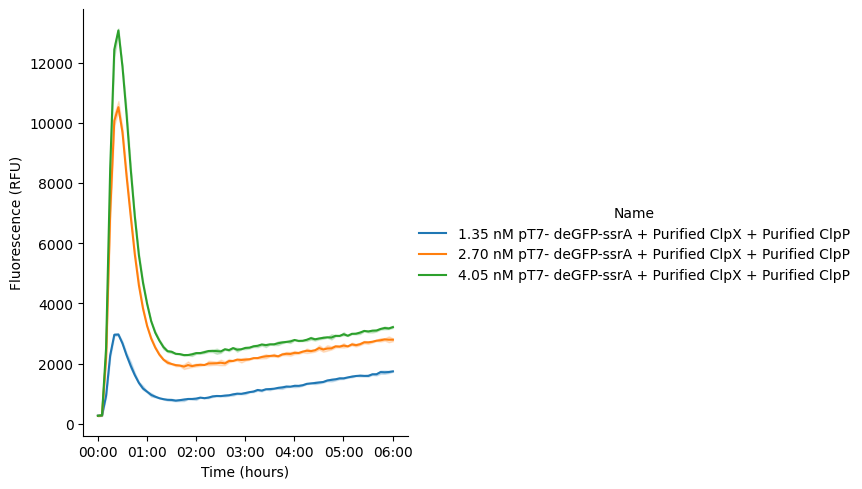

In [5]:
g = pr.plot_curves(data=data)

## Kinetic Analysis
**Metrics extracted:**

  - **Vmax** (`Velocity Max`): Maximum rate of fluorescence increase (slope at inflection point)
  - **Lag time**: Time to reach the exponential phase
  - **Steady-state**: Final fluorescence level and time to reach 95% of asymptote
  - **Drift**: Rate of signal decay or increase after steady-state
  - **R²**: Goodness of fit

In [6]:
# Perform kinetic analysis using sigmoid_drift model
kinetics = pr.kinetic_analysis(
    data=data,
    group_by=['Well','Name'],  # Group by experimental condition
)

kinetics.head()

`Type` column not found in data. All data will be used for kinetic analysis.


Calculating Kinetics


/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


Velocity  \
                                                                             Time   
Well Name                                                                           
N5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 0 days 00:05:19.544304649   
N6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif...           0 days 00:00:00   
N7   4.05 nM pT7- deGFP-ssrA + Purified ClpX + Purif...           0 days 00:00:00   
O5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 0 days 00:05:19.390984818   
O6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif...           0 days 00:00:00   

                                                                           \
                                                          Data        Max   
Well Name                                                                   
N5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 610.55 2496808.65   
N6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 892.84 4464206.88   
N7   4.05 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 992.60 4962986.74   
O5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 659.15 3295772.19   
O6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 897.76 4488805.68   

                                                                              Lag  \
                                                                             Time   
Well Name                                                                           
N5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 0 days 00:05:18.663989456   
N6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif...  -1 days +23:59:59.280000   
N7   4.05 nM pT7- deGFP-ssrA + Purified ClpX + Purif...  -1 days +23:59:59.280000   
O5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif...    0 days 00:05:18.670984   
O6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif...  -1 days +23:59:59.280000   

                                                                 \
                                                           Data   
Well Name                                                         
N5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif...  147.79   
N6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 2397.97   
N7   4.05 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 3176.77   
O5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif...   87.45   
O6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 2379.29   

                                                                     Steady State  \
                                                                             Time   
Well Name                                                                           
N5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 0 days 00:05:20.840320881   
N6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 0 days 00:00:01.059998032   
N7   4.05 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 0 days 00:00:01.059998032   
O5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 0 days 00:05:20.450982850   
O6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 0 days 00:00:01.059998032   

                                                                 \
                                                           Data   
Well Name                                                         
N5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 1160.04   
N6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 1696.40   
N7   4.05 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 1885.93   
O5   1.35 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 1252.39   
O6   2.70 nM pT7- deGFP-ssrA + Purified ClpX + Purif... 1705.75   

                                                                                                       Fit  \
                                                                                                    params   
Well Name                                                                                                    
N5   1.35

## Visualize Fits on Individual Wells

`Type` column not found in data. All data will be used for kinetic analysis.
/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


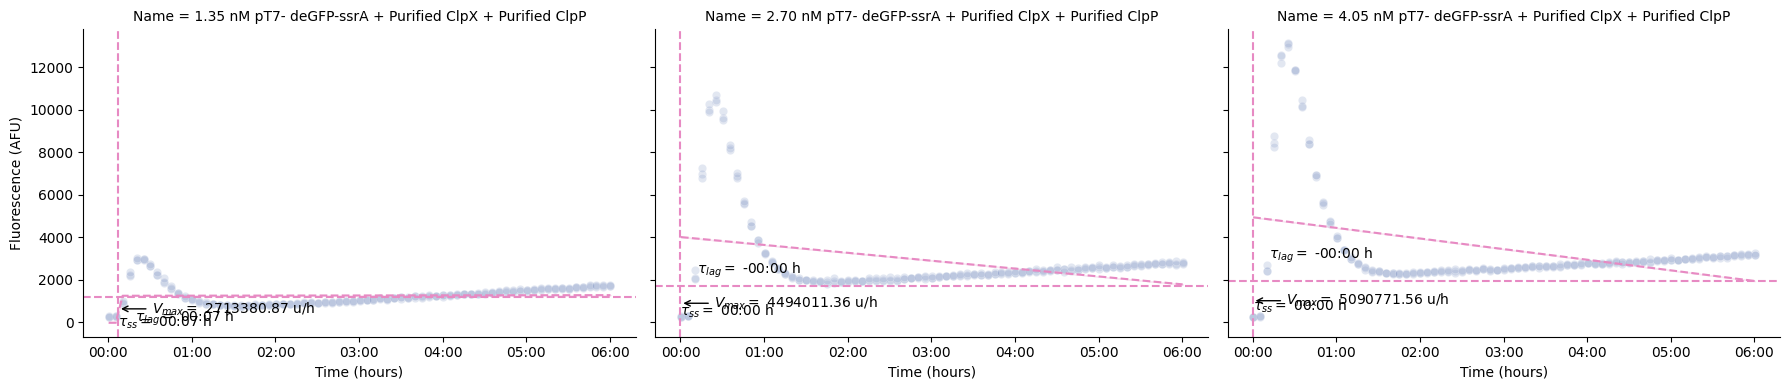

In [7]:
# Plot kinetic fits 
g = pr.plot_kinetics(data, kinetics=kinetics)

## Summary Plots

`Type` column not found in data. All data will be used for kinetic analysis.


Calculating Kinetics


/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)
/opt/anaconda3/envs/bnext-cdk/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: overflow encountered in exp
  result = getattr(ufunc, method)(*inputs, **kwargs)


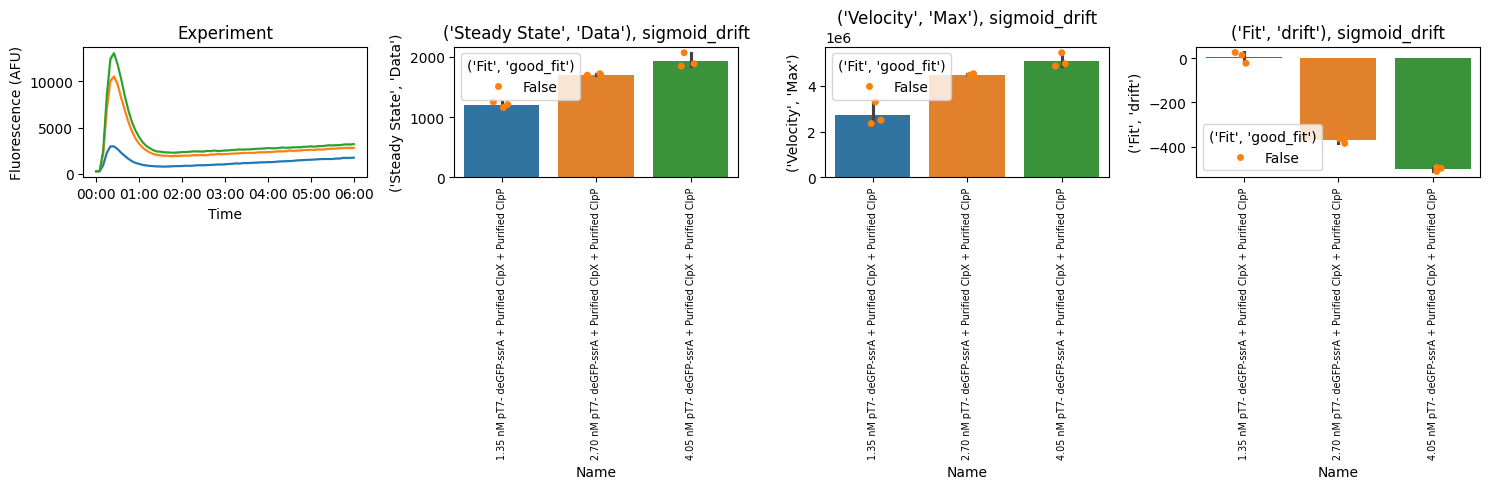

In [8]:
g = pr.plot_summary(data)
# g.savefig("summary.png", dpi=300)

---

## Key Metrics Explained

### 1. **Steady-State Level** (`Steady State, Data`)
- The final fluorescence value reached by the reaction
- Represents the total amount of protein produced
- Higher values indicate greater expression yield

### 2. **Maximum Velocity** (`Velocity, Max`)
- The steepest slope of the fluorescence curve (at the inflection point)
- Units: RFU per second
- Reflects the peak rate of protein synthesis
- Sensitive to enzyme activity, substrate availability, and reaction conditions

### 3. **Lag Time** (`Lag, Time`)
- Time before exponential fluorescence increase begins
- May reflect time for ribosome assembly or initial translation steps
- Shorter lag times suggest faster reaction initiation

### 4. **Drift** (`Fit, drift`)
- Rate of fluorescence change after reaching steady-state
- Positive drift: continued synthesis or aggregation
- Negative drift: photobleaching, protein degradation, or quenching
- Units: RFU per second

### 5. **R² Value** (`Fit, R^2`)
- Goodness of fit (0 to 1, higher is better)
- R² > 0.98 indicates excellent fit
- Poor fits may indicate noisy data, overflow errors, or non-sigmoid kinetics

---

## Tips and Troubleshooting

- **Overflow errors:** Wells with `OVRFLW` or `NaN` values are automatically excluded from fitting
- **Poor fits (low R²):** Inspect raw curves for anomalies (bubbles, evaporation, pipetting errors)
- **Drift:** Sometimes seen in kinetics curves; use `sigmoid_drift` model
- **Multiple replicates:** Always include technical replicates and report error bars
- **Comparing conditions:** Normalize or blank data consistently across all samples

---

## Next Steps

- Export kinetics results: `pr.export_kinetics(kinetics, 'results.csv')`
- Statistical analysis: Use `scipy.stats` or `statsmodels` for ANOVA/t-tests
- Parameter optimization: Vary Mg²⁺, K⁺, or other conditions to maximize Vmax or steady-state
- Mechanistic modeling: Fit ODE models to extract biological rate constants